# 10 — Final Feature Importance and Explainability
**Day 10 · Phase 5: Business Intelligence**

The selected model (Ridge + Gradient Boosting average, log price) is fitted on the **training set only**, and every
importance measure is computed on the **held-out test set**, so the explanations describe behaviour on phones the
model hasn't seen.

### Methods used
1. **Model-internal importance:** standardised Ridge coefficients (log-price effect per 1 SD change) and Gradient
   Boosting impurity importance.
2. **Permutation importance** on the test set, per model input (50 shuffles).
3. **Exact Shapley values** for every test phone (global summary + individual explanations).
4. **Partial dependence / what-if curves:** the average prediction when one specification is changed and everything
   else is kept as is.
5. **Interaction check:** two-way partial dependence vs an additive approximation.

All findings are **associations learned by a model**, not causal effects. They describe how prices in this
dataset are related to specs. They don't say that adding RAM to a given phone would *cause* a retailer to be able to
charge more.

In [1]:
import sys, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.plot_style import (apply_style, save_fig, rupee_axis, PALETTE, PRIMARY, ACCENT,
                            NEUTRAL, DIVERGING, SEQUENTIAL)

apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
RANDOM_STATE = 42

from sklearn.inspection import permutation_importance
from src.train import load_model_ready_data, xy, final_pipeline
from src.feature_engineering import SpecFeatureBuilder, NUMERIC_FEATURES
from src.explain import shapley_matrix, exact_shapley_values
from src.evaluate import regression_metrics

train, test = load_model_ready_data()
X_tr, y_tr, g_tr = xy(train)
X_te, y_te, g_te = xy(test)
model = final_pipeline().fit(X_tr, y_tr)
print("Test metrics of the explained model:", {k: round(v, 3) for k, v in regression_metrics(y_te, model.predict(X_te)).items()})

voting = model.regressor_
ridge_pipe, gb_pipe = voting.named_estimators_["ridge"], voting.named_estimators_["gb"]

Test metrics of the explained model: {'MAE': 2796.204, 'RMSE': 5190.224, 'R2': 0.752, 'MAPE_%': 15.578}


## 1. Model-internal importance

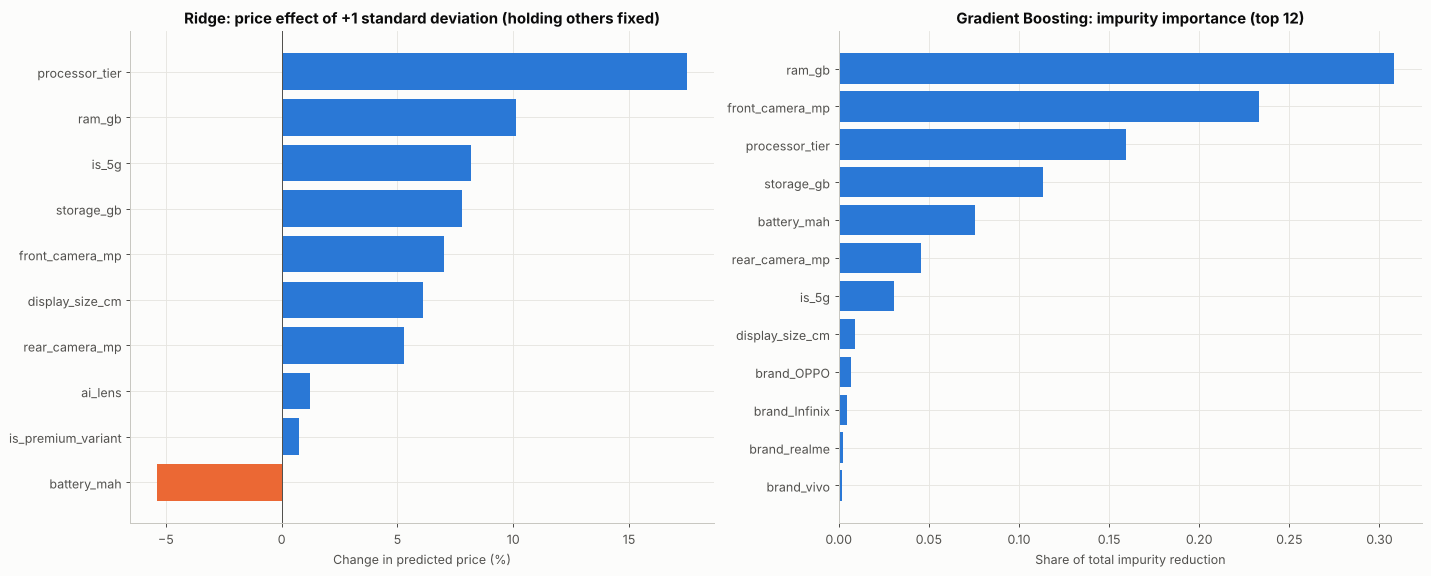

,Ridge % per +1 SD,1 SD equals,GB impurity
ram_gb,10.100,2.006,0.308
front_camera_mp,7.015,9.416,0.233
processor_tier,17.513,0.890,0.159
storage_gb,7.786,60.582,0.113
battery_mah,-5.385,410.268,0.076
rear_camera_mp,5.296,32.423,0.046
is_5g,8.175,0.486,0.031
display_size_cm,6.103,0.363,0.009
ai_lens,1.218,0.223,0.001
is_premium_variant,0.746,0.392,0.000


In [2]:
ridge = ridge_pipe.named_steps["ridge"]
names = ridge_pipe.named_steps["prep"].named_steps["encode"].get_feature_names_out()
coef = pd.Series(ridge.coef_, index=names)
pct = (np.exp(coef) - 1) * 100       # numeric features are standardised: effect of +1 SD
gb = gb_pipe.named_steps["gb"]
gb_names = gb_pipe.named_steps["prep"].named_steps["encode"].get_feature_names_out()
gb_imp = pd.Series(gb.feature_importances_, index=gb_names)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
num_pct = pct[NUMERIC_FEATURES].sort_values()
axes[0].barh(num_pct.index, num_pct.values, color=[ACCENT if v < 0 else PRIMARY for v in num_pct.values])
axes[0].axvline(0, color="#52514e", lw=0.8)
axes[0].set(title="Ridge: price effect of +1 standard deviation (holding others fixed)", xlabel="Change in predicted price (%)")
top_gb = gb_imp.sort_values(ascending=False).head(12).iloc[::-1]
axes[1].barh(top_gb.index, top_gb.values, color=PRIMARY)
axes[1].set(title="Gradient Boosting: impurity importance (top 12)", xlabel="Share of total impurity reduction")
fig.tight_layout(); save_fig(fig, "final_model_internal_importance")

std = SpecFeatureBuilder().transform(X_tr)[NUMERIC_FEATURES].std()
pd.DataFrame({"Ridge % per +1 SD": pct[NUMERIC_FEATURES], "1 SD equals": std, "GB impurity": gb_imp[NUMERIC_FEATURES]}).sort_values("GB impurity", ascending=False).round(3)

In [3]:
brand_effects = pct[[c for c in names if c.startswith("brand_")]].sort_values()
vendor_effects = pct[[c for c in names if c.startswith("processor_vendor_")]].sort_values()
pd.concat([brand_effects.rename("Ridge % vs average"), vendor_effects.rename("Ridge % vs average")]).round(1).to_frame().T

,brand_Infinix,brand_POCO,brand_Motorola,brand_Redmi,brand_Tecno,brand_realme,brand_vivo,brand_infrequent_sklearn,brand_Samsung,brand_OPPO,brand_Google,brand_Apple,processor_vendor_Unknown,processor_vendor_Samsung Exynos,processor_vendor_MediaTek,processor_vendor_Unisoc,processor_vendor_Qualcomm,processor_vendor_Google Tensor,processor_vendor_Apple
Ridge % vs average,-25.400,-20.600,-14.100,-11.100,-10.300,-10.000,0.200,3.500,7.200,15.400,33.800,59.600,-27.600,-14.300,-11.600,-9.300,-5.800,33.800,59.600


**How to read the Ridge panel.** Each bar is the % change in predicted price for a one-standard-deviation increase in
that feature, *holding all other features fixed*. Because the target is log price, effects multiply. One-hot
brand/vendor columns are relative to the average across categories.

**How to read the GB panel.** Share of the boosting model's total variance reduction achieved by splits on each
feature (training data).

**Interpretation.** In the Ridge half, **processor tier has the largest per-SD effect (+17.5 % per ~0.9 tier
step)**, followed by RAM (+10 % per 2 GB), the 5G flag (+8 %), storage (+7.8 % per ~60 GB) and front camera
(+7 % per ~9 MP). Battery is negative (−5.4 % per ~410 mAh). The boosting half splits most on RAM (0.31), front
camera (0.23) and tier (0.16). Both halves rely on the same hardware core but weight it differently, which is part
of why averaging them helps. Brand effects in the Ridge half are large: Apple +60 % and Google +34 % vs the average,
Infinix −25 %, POCO −21 %.

## 2. Permutation importance on the test set

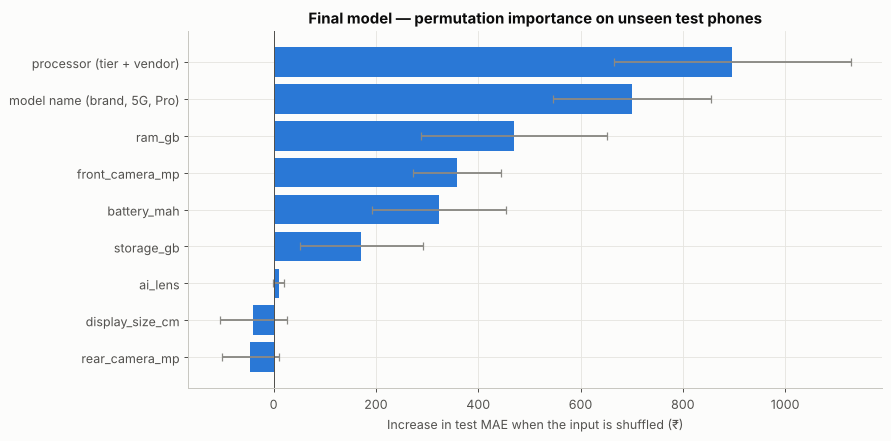

,ΔMAE_mean,ΔMAE_std
processor,897.000,230.800
model,700.700,154.500
ram_gb,469.400,181.800
front_camera_mp,358.500,85.500
battery_mah,322.800,130.700
storage_gb,171.700,120.600
ai_lens,10.200,10.700
display_size_cm,-39.600,65.400
rear_camera_mp,-45.200,56.600


In [4]:
perm = permutation_importance(model, X_te, y_te, scoring="neg_mean_absolute_error", n_repeats=50,
                              random_state=RANDOM_STATE, n_jobs=1)
perm_df = pd.DataFrame({"ΔMAE_mean": perm.importances_mean, "ΔMAE_std": perm.importances_std},
                       index=X_te.columns).sort_values("ΔMAE_mean", ascending=False)
labels = {"processor": "processor (tier + vendor)", "model": "model name (brand, 5G, Pro)"}
fig, ax = plt.subplots(figsize=(10, 5))
p = perm_df.iloc[::-1]
ax.barh([labels.get(i, i) for i in p.index], p["ΔMAE_mean"], xerr=p["ΔMAE_std"], color=PRIMARY, ecolor="#8a8984", capsize=3)
ax.axvline(0, color="#52514e", lw=0.8)
ax.set(title="Final model — permutation importance on unseen test phones", xlabel="Increase in test MAE when the input is shuffled (₹)")
fig.tight_layout(); save_fig(fig, "final_permutation_importance")
perm_df.round(1)

**Interpretation.** On unseen phones, shuffling **processor** raises test MAE by ~₹900 and **model name** (brand, 5G,
Pro) by ~₹700, then RAM (~₹470), front camera (~₹360), battery (~₹320) and storage (~₹170). AI lens, display size
and rear camera are ≈ 0 or slightly negative: the model doesn't need them to price new phones.

## 3. Shapley values for every test phone

In [5]:
background = X_tr.sample(60, random_state=RANDOM_STATE)
sv = shapley_matrix(model, X_te, background, log_space=True)
base_value = exact_shapley_values(model, X_te.iloc[[0]], background, log_space=True).attrs["base_value"]
check = np.allclose(sv.sum(axis=1) + base_value, np.log(model.predict(X_te)), atol=1e-6)
print("Additivity check (base + contributions = log prediction for every phone):", check)
print(f"Base value: log price {base_value:.3f} = ₹{np.exp(base_value):,.0f} (average prediction over the background)")

mean_abs = sv.abs().mean().sort_values(ascending=False)
mean_abs.round(4).to_frame("mean |Shapley| (log price)").assign(**{"≈ typical % effect": (np.exp(mean_abs) - 1).mul(100).round(1)}).T

Additivity check (base + contributions = log prediction for every phone): True
Base value: log price 9.567 = ₹14,282 (average prediction over the background)


,processor,model,ram_gb,storage_gb,front_camera_mp,battery_mah,rear_camera_mp,display_size_cm,ai_lens
mean |Shapley| (log price),0.117,0.110,0.087,0.063,0.057,0.039,0.034,0.026,0.004
≈ typical % effect,12.400,11.600,9.100,6.500,5.900,4.000,3.400,2.600,0.400


**Interpretation.** The additivity check passes: for every test phone, base value (₹14,282) + contributions equals
the model's prediction exactly. The typical size of each input's effect: processor ±12.4 %, model name ±11.6 %,
RAM ±9.1 %, storage ±6.5 %, front camera ±5.9 %, battery ±4 %, rear camera ±3.4 %, display ±2.6 %, AI lens ≈ 0.
The Shapley ranking matches permutation importance at the top.

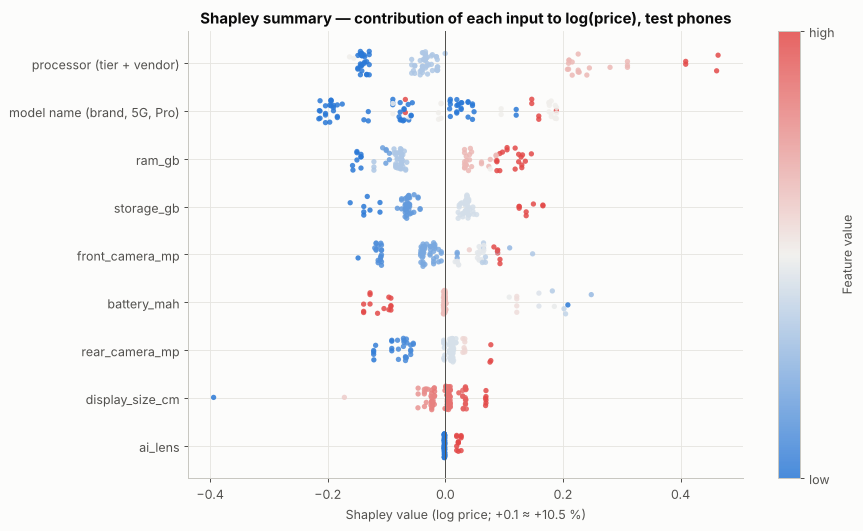

In [6]:
# Summary plot: one dot per test phone, x = contribution, colour = feature value (low → high).
eng = SpecFeatureBuilder().transform(X_te)
colour_source = {"processor": eng["processor_tier"], "model": eng["is_5g"] + eng["is_premium_variant"]}
order = mean_abs.index[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
rng = np.random.default_rng(0)
for i, feat in enumerate(order):
    vals = colour_source.get(feat, X_te[feat]).astype(float)
    norm = (vals - vals.min()) / (vals.max() - vals.min()) if vals.max() > vals.min() else vals * 0 + 0.5
    sc = ax.scatter(sv[feat], i + rng.uniform(-0.25, 0.25, len(sv)), c=norm.fillna(0.5), cmap=DIVERGING, s=18,
                    alpha=0.85, edgecolor="none", vmin=0, vmax=1)
ax.set_yticks(range(len(order)), [labels.get(f, f) for f in order])
ax.axvline(0, color="#52514e", lw=0.8)
ax.set(title="Shapley summary — contribution of each input to log(price), test phones", xlabel="Shapley value (log price; +0.1 ≈ +10.5 %)")
cb = fig.colorbar(sc, ax=ax, ticks=[0, 1]); cb.ax.set_yticklabels(["low", "high"]); cb.set_label("Feature value")
fig.tight_layout(); save_fig(fig, "final_shapley_summary")

**How to read the summary plot.** Each dot is one test phone. Dots to the right raise the predicted price, dots to
the left lower it. Red = high value of that input, blue = low (for `processor` the colour is the tier; for `model`
it's the count of 5G/Pro flags). A feature whose red dots sit on the right has a positive relationship with price.

**Interpretation.** Processor, RAM, storage and front camera show clean red-right / blue-left separation: higher specs
→ higher price. **Battery is reversed** (red dots, i.e. large batteries, on the left). Processor has the widest
spread: flagship chips add up to +0.46 in log price (≈ +58 %). Display size has one large negative outlier, a phone
with an unusually small screen.

## 4. What-if curves (partial dependence)

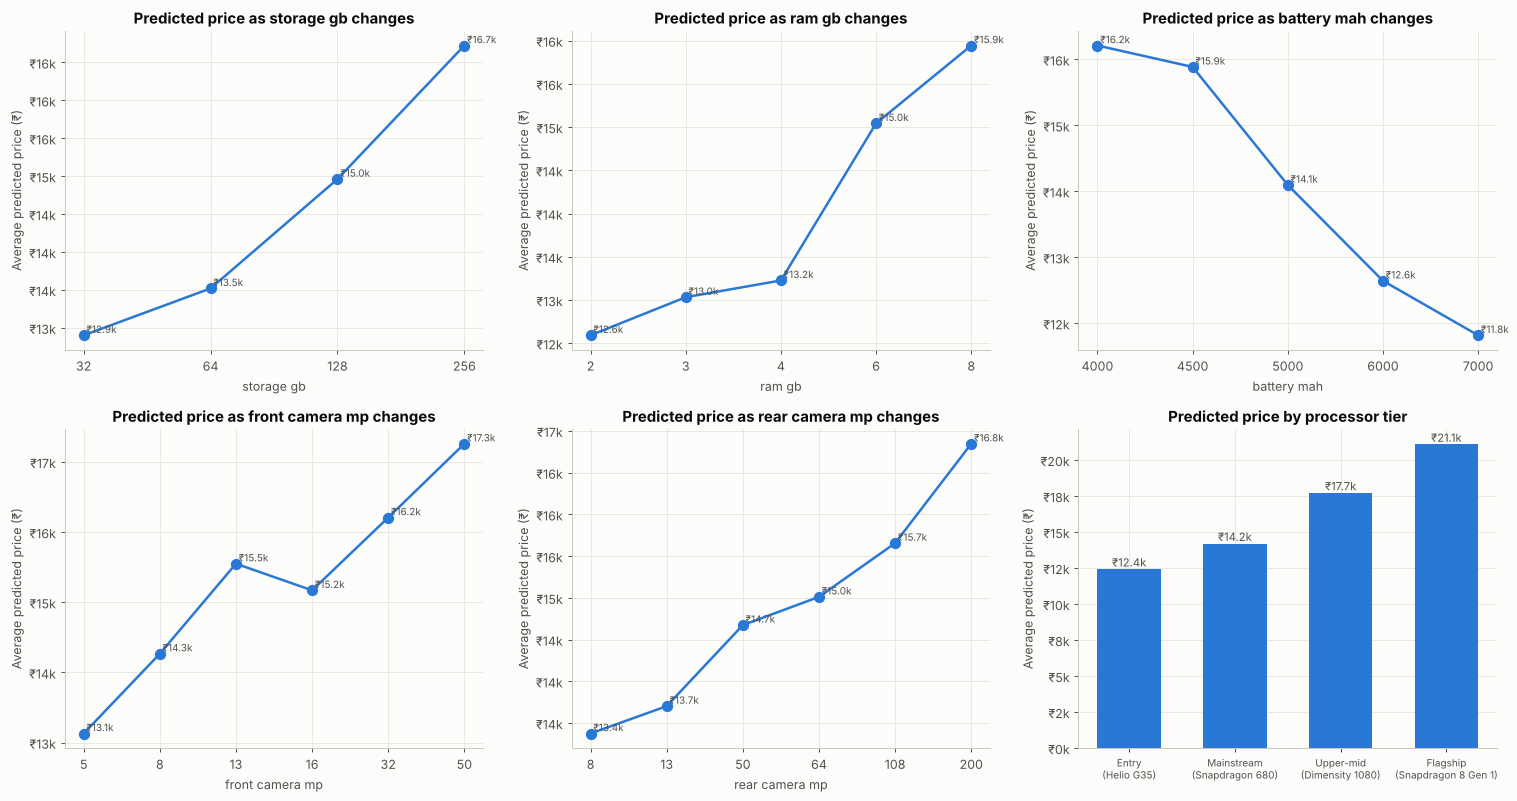

,change,% change in avg prediction
0,storage 64 → 128 GB,10.700
1,storage 128 → 256 GB,11.800
2,RAM 4 → 8 GB,20.500
3,"battery 5,000 → 6,000 mAh",-10.300
4,front camera 8 → 16 MP,6.300
5,rear camera 50 → 108 MP,6.700
6,processor: mainstream → flagship,48.500


In [7]:
def what_if(model, data, column, values):
    out = []
    for v in values:
        d = data.copy(); d[column] = v
        out.append(np.exp(np.mean(np.log(model.predict(d)))))
    return pd.Series(out, index=values)

background_pd = pd.concat([X_tr, X_te])  # all smartphones as the population to average over
curves = {
    "storage_gb": what_if(model, background_pd, "storage_gb", [32, 64, 128, 256]),
    "ram_gb": what_if(model, background_pd, "ram_gb", [2, 3, 4, 6, 8]),
    "battery_mah": what_if(model, background_pd, "battery_mah", [4000, 4500, 5000, 6000, 7000]),
    "front_camera_mp": what_if(model, background_pd, "front_camera_mp", [5, 8, 13, 16, 32, 50]),
    "rear_camera_mp": what_if(model, background_pd, "rear_camera_mp", [8, 13, 50, 64, 108, 200]),
}
chips = {"Entry (Helio G35)": "Mediatek Helio G35", "Mainstream (Snapdragon 680)": "Qualcomm Snapdragon 680",
         "Upper-mid (Dimensity 1080)": "Mediatek Dimensity 1080", "Flagship (Snapdragon 8 Gen 1)": "Qualcomm Snapdragon 8 Gen 1"}
tier_curve = what_if(model, background_pd, "processor", list(chips.values())); tier_curve.index = list(chips.keys())

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, (col, c) in zip(axes.flat, curves.items()):
    ax.plot(c.index.astype(str), c.values, marker="o", ms=8, lw=2, color=PRIMARY)
    for x, v in zip(c.index.astype(str), c.values):
        ax.text(x, v, f" ₹{v/1000:.1f}k", va="bottom", fontsize=8, color="#52514e")
    ax.set(title=f"Predicted price as {col.replace('_', ' ')} changes", xlabel=col.replace("_", " "), ylabel="Average predicted price (₹)")
    rupee_axis(ax)
ax = axes.flat[5]
ax.bar(range(4), tier_curve.values, color=PRIMARY, width=0.6)
ax.set_xticks(range(4), [k.replace(" (", "\n(") for k in tier_curve.index], fontsize=8)
for i, v in enumerate(tier_curve.values):
    ax.text(i, v, f"₹{v/1000:.1f}k", ha="center", va="bottom", fontsize=9, color="#52514e")
ax.set(title="Predicted price by processor tier", ylabel="Average predicted price (₹)"); rupee_axis(ax)
fig.tight_layout(); save_fig(fig, "final_what_if_curves")

effects = pd.DataFrame({
    "change": ["storage 64 → 128 GB", "storage 128 → 256 GB", "RAM 4 → 8 GB", "battery 5,000 → 6,000 mAh",
               "front camera 8 → 16 MP", "rear camera 50 → 108 MP", "processor: mainstream → flagship"],
    "% change in avg prediction": [curves["storage_gb"][128] / curves["storage_gb"][64] - 1,
                                   curves["storage_gb"][256] / curves["storage_gb"][128] - 1,
                                   curves["ram_gb"][8] / curves["ram_gb"][4] - 1,
                                   curves["battery_mah"][6000] / curves["battery_mah"][5000] - 1,
                                   curves["front_camera_mp"][16] / curves["front_camera_mp"][8] - 1,
                                   curves["rear_camera_mp"][108] / curves["rear_camera_mp"][50] - 1,
                                   tier_curve.iloc[3] / tier_curve.iloc[1] - 1],
})
effects["% change in avg prediction"] = (effects["% change in avg prediction"] * 100).round(1)
effects

**How to read these.** Each curve sets one specification to the same value for *all* 516 phones, keeps everything
else as recorded, and averages the predictions (geometric mean). It isolates what the model attributes to that spec
alone. Combinations that don't occur in real phones (e.g. a flagship chip with 2 GB RAM) are part of this average,
which is the main caveat of partial dependence when features are correlated.

**Interpretation.** Processor tier has by far the largest isolated effect: **mainstream → flagship ≈ +49 %**.
Then RAM 4 → 8 GB ≈ +21 %, each storage doubling ≈ +11–12 %, front camera 8 → 16 MP ≈ +6 %, and rear camera
50 → 108 MP ≈ +7% (though permutation showed this doesn't help prediction on unseen phones). Battery 5,000 → 6,000 mAh
is ≈ −10 %.

## 5. Interactions between specifications

Largest interaction deviation: ±1.6%


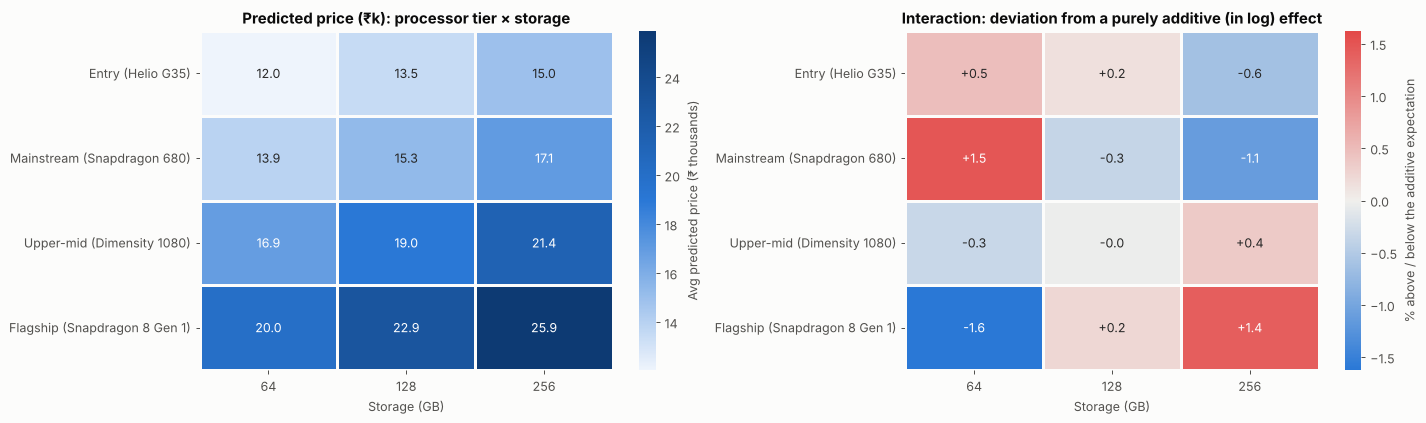

In [8]:
storage_vals = [64, 128, 256]
grid = pd.DataFrame(index=list(chips.keys()), columns=storage_vals, dtype=float)
sample = background_pd.sample(150, random_state=RANDOM_STATE)
for name, chip in chips.items():
    for s in storage_vals:
        d = sample.copy(); d["processor"] = chip; d["storage_gb"] = s
        grid.loc[name, s] = np.mean(np.log(model.predict(d)))
row_eff = grid.mean(axis=1); col_eff = grid.mean(axis=0); overall = grid.values.mean()
additive = pd.DataFrame(row_eff.values[:, None] + col_eff.values[None, :] - overall, index=grid.index, columns=grid.columns)
interaction_pct = (np.exp(grid - additive) - 1) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
sns.heatmap(np.exp(grid) / 1000, annot=True, fmt=".1f", cmap=SEQUENTIAL, ax=axes[0], cbar_kws={"label": "Avg predicted price (₹ thousands)"},
            linewidths=1, linecolor="#fcfcfb")
axes[0].set(title="Predicted price (₹k): processor tier × storage", xlabel="Storage (GB)", ylabel=""); axes[0].grid(False)
lim = max(1, np.abs(interaction_pct.values).max())
sns.heatmap(interaction_pct, annot=True, fmt="+.1f", cmap=DIVERGING, vmin=-lim, vmax=lim, ax=axes[1],
            cbar_kws={"label": "% above / below the additive expectation"}, linewidths=1, linecolor="#fcfcfb")
axes[1].set(title="Interaction: deviation from a purely additive (in log) effect", xlabel="Storage (GB)", ylabel=""); axes[1].grid(False)
fig.tight_layout(); save_fig(fig, "final_interaction_tier_storage")
print("Largest interaction deviation: ±{:.1f}%".format(np.abs(interaction_pct.values).max()))

In [9]:
# Battery × processor tier — is the negative battery effect the same in every tier?
batt_vals = [4500, 5000, 6000]
g2 = pd.DataFrame(index=list(chips.keys()), columns=batt_vals, dtype=float)
for name, chip in chips.items():
    for b in batt_vals:
        d = sample.copy(); d["processor"] = chip; d["battery_mah"] = b
        g2.loc[name, b] = np.exp(np.mean(np.log(model.predict(d))))
(g2.div(g2[5000], axis=0).sub(1).mul(100)).round(1).rename(columns=lambda c: f"{c} mAh vs 5000 (%)")

,4500 mAh vs 5000 (%),5000 mAh vs 5000 (%),6000 mAh vs 5000 (%)
Entry (Helio G35),14.000,0.000,-9.900
Mainstream (Snapdragon 680),14.000,0.000,-10.600
Upper-mid (Dimensity 1080),11.200,0.000,-9.900
Flagship (Snapdragon 8 Gen 1),13.700,0.000,-10.600


**How to read the interaction maps.** The left map is the average predicted price for each processor-tier × storage
combination. The right map compares it with what a purely additive (in log, i.e. multiplicative) model would give.
Values near 0 % mean the two specs act independently; larger deviations mean the effect of one depends on the other.
Because half of the final model is linear (strictly additive in log space), interactions can only come from the
boosting half and are muted.

**Interpretation.** The largest deviation from additivity is **±1.6 %**: processor tier and storage act almost
independently in log space, i.e. their effects **multiply**. The battery table shows the same story: 6,000 vs
5,000 mAh lowers predictions by ~10 % in every tier. Interactions are not an important part of this pricing pattern.

## 6. Individual prediction explanations

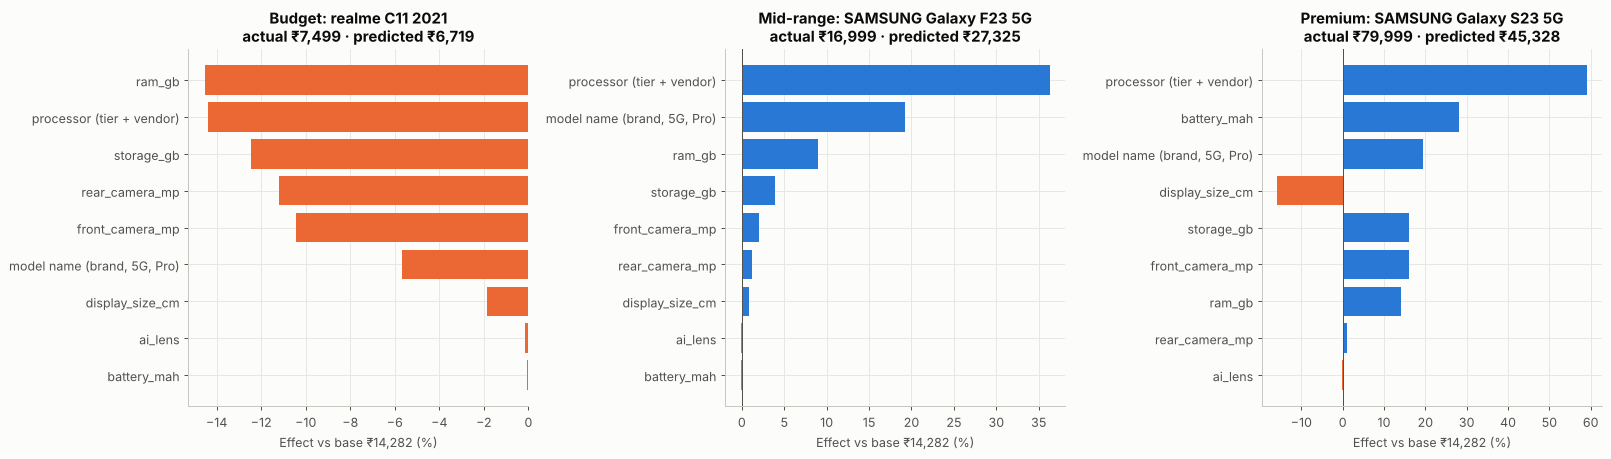

,segment,model,processor,storage_gb,ram_gb,battery_mah,rear_camera_mp,front_camera_mp,price,predicted
491,Budget,realme C11 2021,Octa-core,32,2.000,5000,8,5,7499,"6,719.000"
108,Mid-range,SAMSUNG Galaxy F23 5G,Qualcomm Snapdragon 750G,128,6.000,5000,50,8,16999,"27,325.000"
511,Premium,SAMSUNG Galaxy S23 5G,Qualcomm Snapdragon 8 Gen 2,256,8.000,3900,50,12,79999,"45,328.000"


In [10]:
pred_te = pd.Series(model.predict(X_te), index=X_te.index)
picks = {
    "Budget": (y_te - 7500).abs().idxmin(),
    "Mid-range": (y_te - 17000).abs().idxmin(),
    "Premium": y_te.idxmax(),
}
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
for ax, (label, idx) in zip(axes, picks.items()):
    contrib = sv.loc[idx].sort_values(key=np.abs, ascending=True)
    pct_c = (np.exp(contrib) - 1) * 100
    ax.barh([labels.get(f, f) for f in contrib.index], pct_c.values, color=[PRIMARY if v > 0 else ACCENT for v in pct_c.values])
    ax.axvline(0, color="#52514e", lw=0.8)
    row = test.loc[idx]
    ax.set(title=f"{label}: {row['model']}\nactual ₹{row['price']:,.0f} · predicted ₹{pred_te[idx]:,.0f}",
           xlabel=f"Effect vs base ₹{np.exp(base_value):,.0f} (%)")
fig.tight_layout(); save_fig(fig, "final_individual_explanations")

explained = test.loc[list(picks.values()), ["model", "processor", "storage_gb", "ram_gb", "battery_mah",
                                            "rear_camera_mp", "front_camera_mp", "price"]]
explained.insert(0, "segment", list(picks.keys()))
explained.assign(predicted=pred_te[list(picks.values())].round(0).values)

**How to read these.** Each bar is that input's multiplicative effect relative to the base prediction
(the average phone, ₹≈13–14k). Applying them in sequence (base × (1+e₁) × (1+e₂) …) gives exactly the model's
prediction. This is the explanation a pricing analyst could attach to any individual estimate.

**Interpretation.**
- **Budget (realme C11 2021, ₹7,499 → predicted ₹6,719):** every hardware input pulls the price down from the
  ₹14.3k base (2 GB RAM −15 %, unknown/entry processor −14 %, 32 GB −12 %, low-res cameras −10–11 %). A good estimate.
- **Mid-range (Galaxy F23 5G, ₹16,999 → ₹27,325):** an upper-mid Snapdragon 750G (+36 %) and Samsung/5G name
  signals (+19 %) push the estimate up, but the phone sold at a mainstream price — see §8.
- **Premium (Galaxy S23, ₹79,999 → ₹45,328):** flagship chip +59 %; the small 3,900 mAh battery reads as a premium
  signal (+28 %); still far below the real price.

## 7. Comparing the importance methods

In [11]:
cmp = pd.DataFrame({
    "permutation ΔMAE (₹)": perm_df["ΔMAE_mean"],
    "mean |Shapley|": mean_abs,
})
rel = pd.read_csv(PROJECT_ROOT / "reports" / "feature_relevance.csv", index_col=0)
to_input = lambda c: "processor" if c.startswith(("processor_", "processor")) else ("model" if c.startswith(("brand", "is_5g", "is_premium")) else c)
cmp["Spearman |ρ| (Day 5, max)"] = rel["|spearman|"].groupby(to_input).max()
gb_in = gb_imp.groupby(to_input).sum(); cmp["GB impurity (sum)"] = gb_in
ranks = cmp.rank(ascending=False).astype(int).add_suffix(" rank")
final_importance = cmp.join(ranks).sort_values("permutation ΔMAE (₹) rank")
final_importance.to_csv(PROJECT_ROOT / "reports" / "final_feature_importance.csv")
final_importance.round(3)

,permutation ΔMAE (₹),mean |Shapley|,"Spearman |ρ| (Day 5, max)",GB impurity (sum),permutation ΔMAE (₹) rank,mean |Shapley| rank,"Spearman |ρ| (Day 5, max) rank",GB impurity (sum) rank
processor,897.039,0.117,0.859,0.162,1,1,1,3
model,700.706,0.110,0.597,0.052,2,2,5,6
ram_gb,469.448,0.087,0.796,0.308,3,3,3,1
front_camera_mp,358.527,0.057,0.789,0.233,4,5,4,2
battery_mah,322.785,0.039,0.458,0.076,5,6,7,5
storage_gb,171.725,0.063,0.814,0.113,6,4,2,4
ai_lens,10.217,0.004,0.191,0.001,7,9,9,9
display_size_cm,-39.584,0.026,0.222,0.009,8,8,8,8
rear_camera_mp,-45.243,0.034,0.573,0.046,9,7,6,7


## 8. Answers to the business questions
(The numbers come from the outputs above, which were run on unseen test phones.)

**Method agreement.** Permutation importance and mean |Shapley| give the **same top three** (processor, model name,
RAM). Day 5's correlation ranking agrees on processor and RAM but over-rates **storage** (2nd by correlation, 6th by
permutation) and **rear camera**. GB impurity ranks RAM and front camera first, the training-data bias seen on Day 6.

| Question | Answer from the results |
|---|---|
| **Does RAM have a strong relationship with price?** | **Yes.** 3rd by permutation (+₹469 MAE when shuffled) and Shapley (typical ±9 %). With everything else fixed, moving all phones from 4 → 8 GB raises the average prediction by **~20 %**. Likely *understated*: RAM is capped at 8 GB and missing for 15 premium rows. |
| **How does storage relate to price?** | Strongly *associated* (ρ = 0.81) and each doubling adds **~11–12 %** to the average prediction (64→128: +10.7 %; 128→256: +11.8 %). But it ranks only 6th by permutation (+₹172): once RAM and processor are known, storage adds less new information, because manufacturers bundle them. |
| **Does camera specification add predictive information?** | **Front camera: yes, moderately** (4th, +₹359; 8 → 16 MP ≈ +6 %). **Rear camera megapixels: no.** Permutation importance is slightly negative (−₹45): on unseen phones, MP count doesn't help, because 12 MP iPhones/Pixels/S-series are premium while 50 MP is everywhere. |
| **Does processor information improve prediction?** | **It is the single most important input** (+₹897 MAE when shuffled; typical Shapley effect ±12 %). Moving all phones from a mainstream chip (Snapdragon 680) to a flagship chip (Snapdragon 8 Gen 1) raises the average prediction by **~49 %**. The Day 4 tier extraction is what makes this usable. |
| **Does battery capacity strongly influence predictions?** | It has a **moderate, negative** effect (5th, +₹323): 5,000 → 6,000 mAh lowers the average prediction by **~10 %**, and 4,500 vs 5,000 mAh raises it by 11–14 %, consistently in every processor tier. Large batteries mark budget positioning; this is association, not a cost penalty for batteries. |
| **Brand / model name?** | **2nd most important** (+₹701). Relative to the average, the Ridge part gives Apple +60 %, Google +34 %, OPPO +15 %, Samsung +7 %, vs Infinix −25 %, POCO −21 % (Apple/Google brand and chip columns are identical, so their effect is shared). |
| **Are there interactions?** | **Weak.** In log space, processor tier × storage deviates from a purely additive pattern by at most ±1.6 %, and the battery effect is the same across tiers. Spec effects behave approximately **multiplicatively**: each upgrade adds a roughly constant *percentage*, whatever the rest of the phone. (Half the model is linear, which mutes interactions; GB alone found none strong enough to improve CV in Day 8.) |
| **AI lens / display size?** | Practically no predictive value (permutation ≈ 0 or negative). |

**Unexpected findings, investigated.**
- The mid-range example (Galaxy F23 5G) is over-predicted by ₹10k. Its explanation shows why: the Snapdragon 750G
  (upper-mid tier) contributes +36 % and the model-name signals (5G, Samsung) +19 %. On paper it's an upper-mid
  phone; in the market it was sold at a mainstream price. **Launch date / model age isn't in the data**, so the model
  can't discount older chips.
- The Galaxy S23 is under-predicted by ₹35k even though its processor contributes +59 %. Its small battery
  (3,900 mAh) and compact display read as flagship signals, but the model has seen very few ₹50k+ phones and
  can't reach the S23's price level. Premium pricing is where the model is weakest.

**Limitations of these explanations.** They describe the model, not causation. Correlated specs share credit (the
storage vs RAM split is partly arbitrary). Partial-dependence curves average over spec combinations that don't exist
in real phones. The test set is small (35 models), so ranks separated by small margins (e.g. front camera vs battery)
aren't reliable.